### Standardization 


For models like: SVM, logistic regression

#### random state value: 44

Take out only hipothesis features

In [19]:
required_features = [
    'ROA(A) before interest and % after tax', #
    'Research and development expense rate', #
    'Total debt/Total net worth', #
    'Debt ratio %', #
    'Cash Flow to Liability', #
    'Revenue Per Share (Yuan ¥)', # 
    'Current Liabilities/Equity', #
    'Net Income to Total Assets', #
    'Borrowing dependency', #
    'Allocation rate per person', #
    'Bankrupt?'
]

Shuffling and splitting dataset


In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme()

data = pd.read_csv('./content/data.csv', sep=',')
data.columns = data.columns.str.strip() # MUST HAVE
filtered_data = data[required_features]

data_shuffled = filtered_data.sample(frac=1, random_state=44)

train_end = int(0.6 * len(data_shuffled))
val_end = int(0.8 * len(data_shuffled))

train_data = data_shuffled.iloc[:train_end].copy()
val_data = data_shuffled.iloc[train_end:val_end].copy()
test_data = data_shuffled.iloc[val_end:].copy()

y_train = train_data['Bankrupt?'] == 1
y_val = val_data['Bankrupt?'] == 1 
y_test = test_data['Bankrupt?'] == 1

train_data = train_data.drop(columns=['Bankrupt?'])
val_data = val_data.drop(columns=['Bankrupt?'])
test_data = test_data.drop(columns=['Bankrupt?'])


### Performing standardization

In [25]:
from sklearn.preprocessing import (
StandardScaler,
)

standard_scaler = StandardScaler().set_output(transform='pandas')
train_standard = standard_scaler.fit_transform(train_data)



Quick visualisation

<Figure size 1000x800 with 0 Axes>

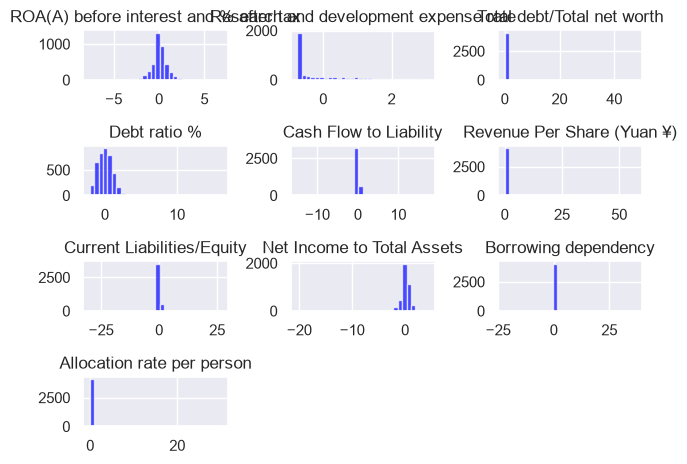

In [28]:
plt.figure(figsize=(10, 8))
train_standard.hist(bins=30, color='blue', alpha=0.7)
plt.tight_layout()
